Hierarchical Projects

In [1]:
import numpy as np 
import pandas as pd
from scipy import ndimage 
from scipy.cluster import hierarchy 
from scipy.spatial import distance_matrix 
from matplotlib import pyplot as plt 
from sklearn import manifold, datasets 
from sklearn.cluster import AgglomerativeClustering 
from sklearn.datasets import make_blobs 
from scipy.cluster.hierarchy import fcluster
import pylab 

In [2]:
cust_df = pd.read_csv("1632560262896716.csv")
cust_df.shape


(200, 5)

In [3]:
cust_df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cust_df['Gender'] = le.fit_transform(cust_df['Gender'])  # Male=1, Female=0

In [5]:
cust_df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


In [6]:
featureset = cust_df[['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

In [7]:
from sklearn.preprocessing import MinMaxScaler
x = featureset.values
min_max_scaler = MinMaxScaler()
feature_mtx = min_max_scaler.fit_transform(x)
feature_mtx[0:5]

array([[1.        , 0.01923077, 0.        , 0.3877551 ],
       [1.        , 0.05769231, 0.        , 0.81632653],
       [0.        , 0.03846154, 0.00819672, 0.05102041],
       [0.        , 0.09615385, 0.00819672, 0.7755102 ],
       [0.        , 0.25      , 0.01639344, 0.39795918]])

In [8]:
#from sklearn.metrics.pairwise import euclidean_distances
#dist_matrix = euclidean_distances(feature_mtx , feature_mtx)
#print(dist_matrix)

In [9]:
# روش اول: مستقیماً به linkage بدیم
Z_using_dist_matrix = hierarchy.linkage(feature_mtx, method='complete', metric='euclidean')

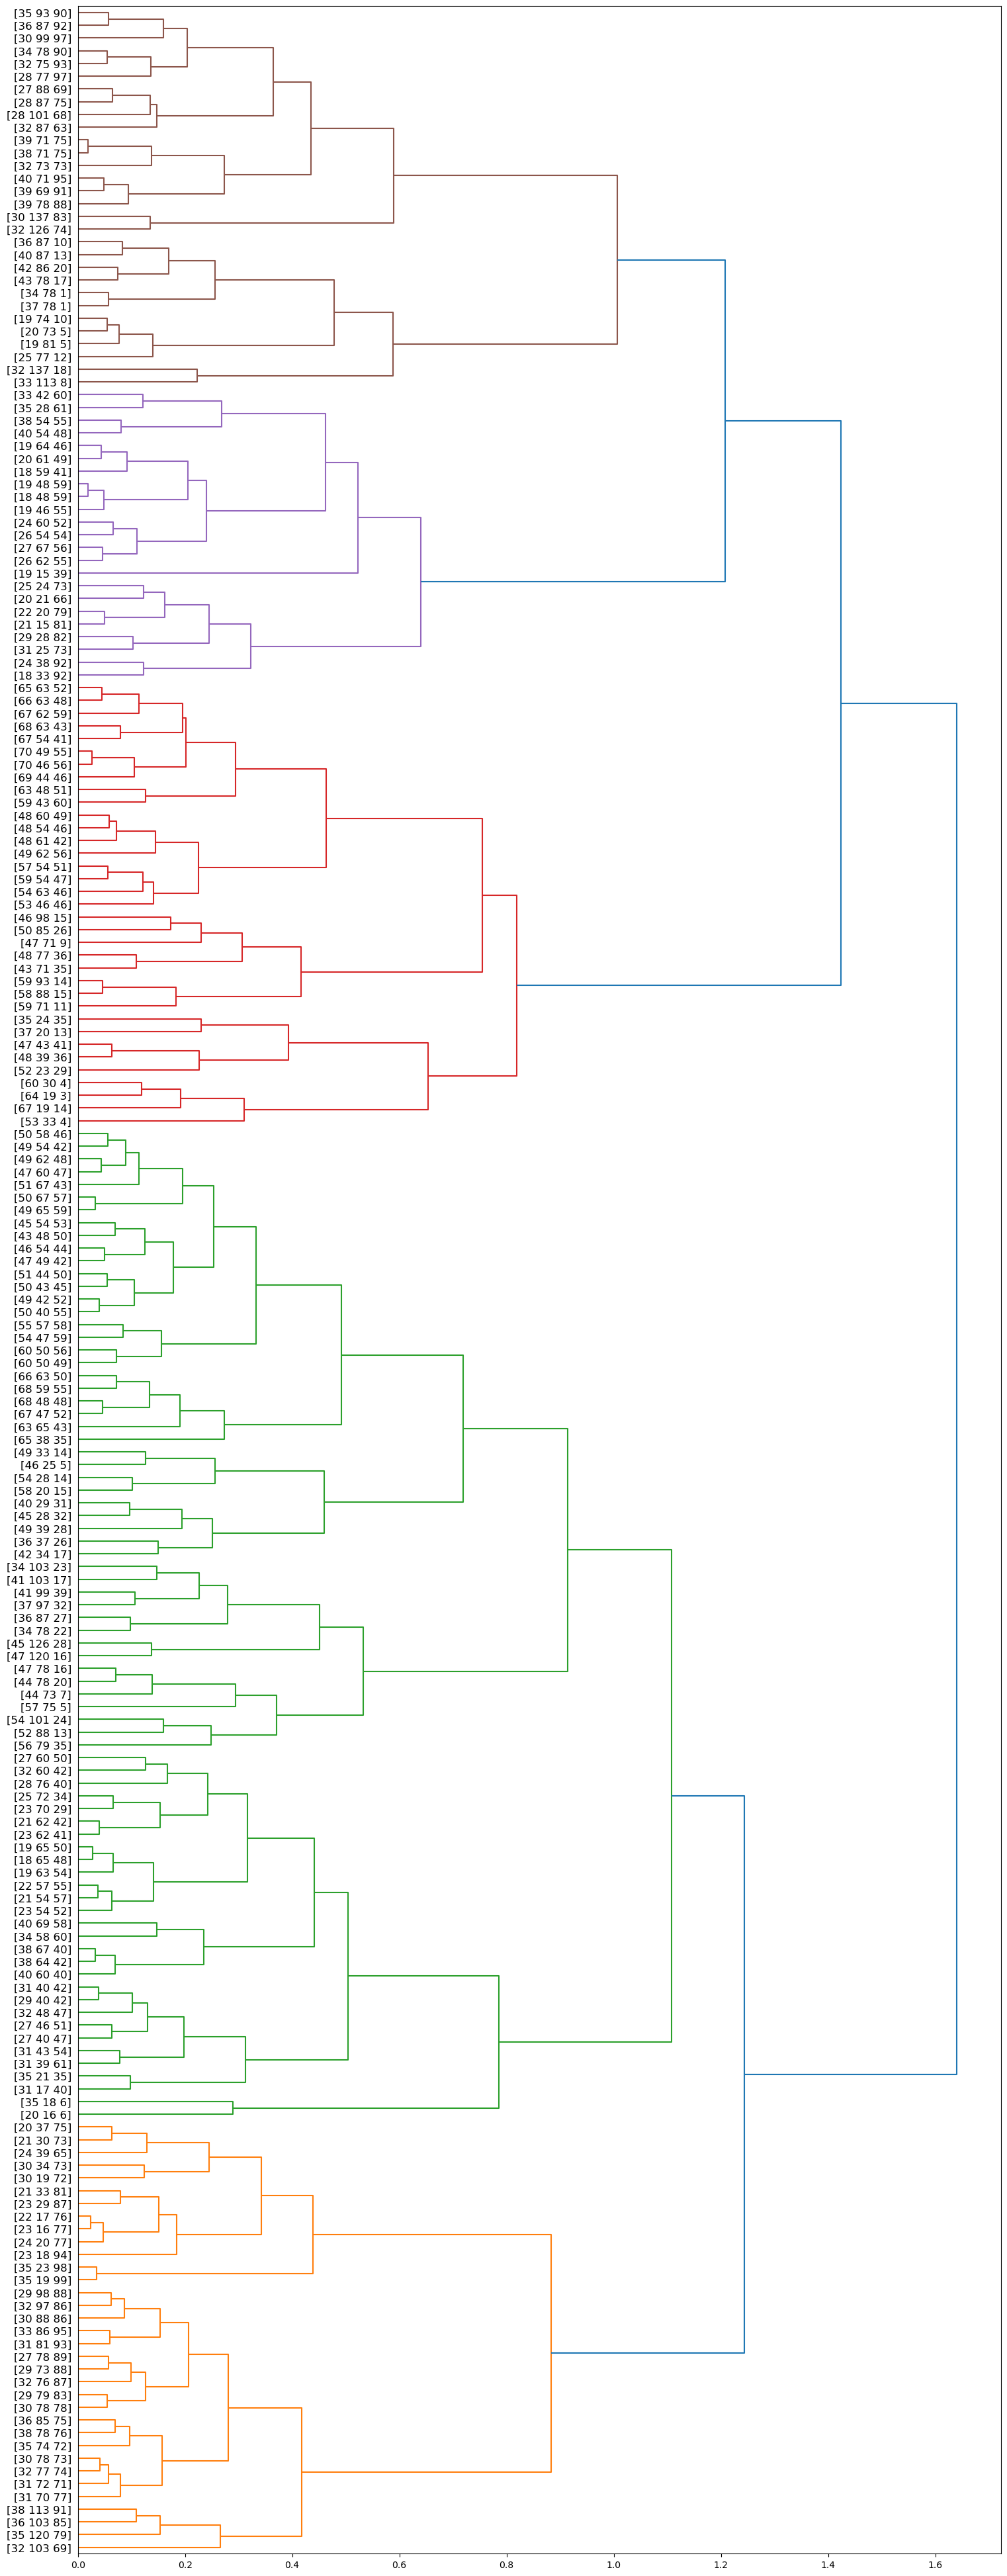

In [10]:
fig = pylab.figure(figsize=(18,50))
def llf(id):
    return '[%s %s %s]'  % (cust_df['Age'][id], cust_df['Annual Income (k$)'][id], cust_df['Spending Score (1-100)'][id]  )

dendro = hierarchy.dendrogram(Z_using_dist_matrix ,  leaf_label_func=llf, leaf_rotation=0, leaf_font_size =12, orientation = 'right')